# Subgroup Analysis 

The models will be rescored separately within slices of the cohort, in this case based on IDH testing method, scanner make, and scanner strength. 

**Purpose**: a consistency check to determine if the models are recognizing patterns associated with specific subgroups. Essentially, are the models finding shortcuts during learning to pickup non-biological features to improve model performance. In `01_metadata_manifest.ipynb`scanner_make had different mutant rates, which could possibly translate to the models. For instance, Philips MRI had 34.8% mutants while Siemens MRI had 24.1%. 

For each subgroup, some groups may have small sample sizes which would be noisy and not be very informative so they are excluded. A basic rule applied here is that there is at least 20 mutants and 20 wildtypes for that specific group. 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from src.cohort import build_cohort
from src.config import OOF_PATH

MIN_PER_CLASS = 20          # fixed before seeing any subgroup AUROC
N_BOOT, SEED = 1000, 42
sub_cols = ["scanner_make", "scanner_group", "idh_method"]

cohort = build_cohort(verbose=False)
oof = pd.read_csv(OOF_PATH)

# Built once from scratch, with age included, so rerunning never duplicates columns.
df = oof.merge(cohort[["patient_id", "age"] + sub_cols],
               on="patient_id", how="left", validate="one_to_one")
df["avg_age_image_prob"] = (df["clinical_age_prob"] + df["image_cnn_v2_prob"]) / 2

assert len(df) == 617
assert df[["age"] + sub_cols].notna().all().all()

# The Distribution of Each Subgroup
The 3 subgroups analyzed: 
- `scanner_make` - MRI brand/manufacturer
- `scanner_group` - strength of the MRI
- `idh_method` - IDH testing method; either NGS or IHC 

In [2]:
def describe(col):
    g = df.groupby(col)
    t = pd.DataFrame({"n": g.size(), "mutant": g["idh"].sum().astype(int)})
    t["wildtype"] = t["n"] - t["mutant"]
    t["mutant %"] = (100 * t["mutant"] / t["n"]).round(1)
    t["median age"] = g["age"].median()
    t["age IQR"] = g["age"].apply(lambda a: f"{a.quantile(.25):.0f} to {a.quantile(.75):.0f}")
    t["AUROC estimated"] = np.where(t[["mutant", "wildtype"]].min(axis=1) >= MIN_PER_CLASS, "yes", "no")
    t.index = pd.MultiIndex.from_product([[col], t.index], names=["variable", "level"])
    return t

cohort_table = pd.concat([describe(c) for c in sub_cols])
cohort_table

n  mutant  wildtype  mutant %  median age  \
variable      level                                                       
scanner_make  GE            170      50       120      29.4        54.0   
              Hitachi        15       4        11      26.7        64.0   
              Not Reported   27       8        19      29.6        63.0   
              Philips       140      49        91      35.0        60.0   
              Siemens       264      63       201      23.9        58.0   
              Toshiba         1       1         0     100.0        32.0   
scanner_group 1.5T          378     109       269      28.8        57.0   
              3T            195      53       142      27.2        59.0   
              other          17       5        12      29.4        55.0   
              unreported     27       8        19      29.6        63.0   
idh_method    IHC           408     103       305      25.2        62.0   
              NGS           209      72       137      34.4        51.0   

                             age IQR AUROC estimated  
variable      level                                   
scanner_make  GE            40 to 66             yes  
              Hitachi       50 to 66              no  
              Not Reported  51 to 68              no  
              Philips       43 to 68             yes  
              Siemens       46 to 68             yes  
              Toshiba       32 to 32              no  
scanner_group 1.5T          42 to 68             yes  
              3T            45 to 68             yes  
              other         41 to 65              no  
              unreported    51 to 68              no  
idh_method    IHC           49 to 70             yes  
              NGS           38 to 62             yes

In [3]:
# Do scanner_make and idh_method overlap? 
overlap = pd.crosstab(df["scanner_make"], df["idh_method"])
overlap["% NGS"] = (100 * overlap["NGS"] / overlap[["IHC", "NGS"]].sum(axis=1)).round(0).astype(int)
overlap

idh_method,IHC,NGS,% NGS
scanner_make,,,
GE,110,60,35
Hitachi,10,5,33
Not Reported,13,14,52
Philips,100,40,29
Siemens,175,89,34
Toshiba,0,1,100


### Subgroup AUROC Table

The AUROC with a patient-level bootstrap applied to each subgroup. The goal here is to see if the AUROC values hold across groups and subgroups. If AUROC holds within each group it agrues against the models relying on the scanner idenity or the testing method.  

In [4]:
models = {
    "age-only":      "clinical_age_prob",
    "image v2":      "image_cnn_v2_prob",
    "fused":         "fused_cnn_prob",
    "50/50 average": "avg_age_image_prob",
}

def auroc_ci(y, p):
    """AUROC with a patient-level bootstrap 95% CI. Same seed on every call, so all
    models in a subgroup see the same resampled patients."""
    rng = np.random.default_rng(SEED)
    y, p = np.asarray(y), np.asarray(p)
    boots = []
    for _ in range(N_BOOT):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() == y[i].max():      # resample with only one class
            continue
        boots.append(roc_auc_score(y[i], p[i]))
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return roc_auc_score(y, p), lo, hi

rows = []
def add(variable, level, g):
    n_mut = int(g["idh"].sum())
    n_wt = len(g) - n_mut
    for name, col in models.items():
        r = {"variable": variable, "level": level, "model": name,
             "n": len(g), "mutant": n_mut, "wildtype": n_wt}
        if min(n_mut, n_wt) >= MIN_PER_CLASS:
            r["auroc"], r["lo"], r["hi"] = auroc_ci(g["idh"], g[col])
        rows.append(r)           # subgroups below the rule keep NaN

add("all patients", "all", df)
for col in sub_cols:
    for level, g in df.groupby(col):
        add(col, level, g)

sub_long = pd.DataFrame(rows)

In [5]:
est = sub_long.dropna(subset=["auroc"]).copy()
est["AUROC (95% CI)"] = est.apply(lambda r: f"{r.auroc:.3f} ({r.lo:.3f} to {r.hi:.3f})", axis=1)

subgroup_table = (est.pivot(index=["variable", "level", "n", "mutant"],
                            columns="model", values="AUROC (95% CI)")[list(models)])
subgroup_table

model                                           age-only  \
variable      level   n   mutant                           
all patients  all     617 175     0.880 (0.853 to 0.909)   
idh_method    IHC     408 103     0.900 (0.867 to 0.931)   
              NGS     209 72      0.839 (0.782 to 0.892)   
scanner_group 1.5T    378 109     0.895 (0.860 to 0.926)   
              3T      195 53      0.867 (0.815 to 0.917)   
scanner_make  GE      170 50      0.864 (0.805 to 0.919)   
              Philips 140 49      0.905 (0.852 to 0.951)   
              Siemens 264 63      0.893 (0.847 to 0.934)   

model                                           image v2  \
variable      level   n   mutant                           
all patients  all     617 175     0.907 (0.880 to 0.930)   
idh_method    IHC     408 103     0.912 (0.883 to 0.942)   
              NGS     209 72      0.899 (0.850 to 0.941)   
scanner_group 1.5T    378 109     0.918 (0.888 to 0.943)   
              3T      195 53      0.881 (0.819 to 0.937)   
scanner_make  GE      170 50      0.889 (0.835 to 0.935)   
              Philips 140 49      0.917 (0.867 to 0.960)   
              Siemens 264 63      0.907 (0.862 to 0.947)   

model                                              fused  \
variable      level   n   mutant                           
all patients  all     617 175     0.922 (0.894 to 0.947)   
idh_method    IHC     408 103     0.929 (0.900 to 0.955)   
              NGS     209 72      0.910 (0.861 to 0.951)   
scanner_group 1.5T    378 109     0.929 (0.898 to 0.955)   
              3T      195 53      0.909 (0.847 to 0.959)   
scanner_make  GE      170 50      0.900 (0.846 to 0.943)   
              Philips 140 49      0.922 (0.871 to 0.966)   
              Siemens 264 63      0.938 (0.897 to 0.971)   

model                                      50/50 average  
variable      level   n   mutant                          
all patients  all     617 175     0.929 (0.907 to 0.950)  
idh_method    IHC     408 103     0.938 (0.911 to 0.961)  
              NGS     209 72      0.915 (0.868 to 0.953)  
scanner_group 1.5T    378 109     0.945 (0.921 to 0.966)  
              3T      195 53      0.904 (0.853 to 0.950)  
scanner_make  GE      170 50      0.906 (0.856 to 0.949)  
              Philips 140 49      0.943 (0.899 to 0.978)  
              Siemens 264 63      0.940 (0.905 to 0.967)

### Forest Plot

To visualize the results of the AUROC bootstrap table above.  

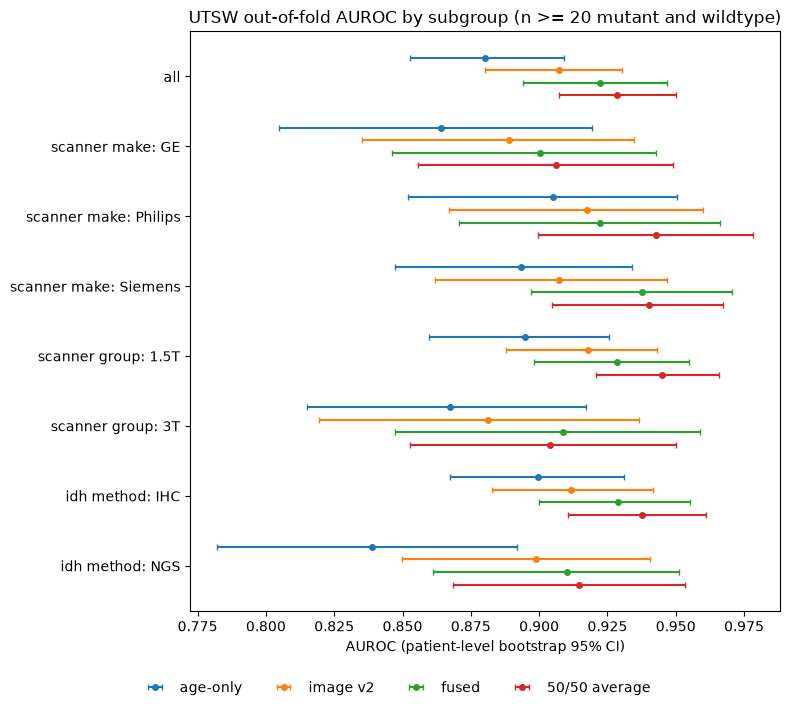

In [6]:
groups = est[["variable", "level"]].drop_duplicates().reset_index(drop=True)
labels = [l if v == "all patients" else f"{v.replace('_', ' ')}: {l}"
          for v, l in zip(groups["variable"], groups["level"])]

fig, ax = plt.subplots(figsize=(8, 0.7 * len(groups) + 1.5))
offsets = np.linspace(-0.27, 0.27, len(models))
for off, name in zip(offsets, models):
    s = est[est["model"] == name].merge(groups.reset_index(), on=["variable", "level"])
    ax.errorbar(s["auroc"], s["index"] + off,
                xerr=[s["auroc"] - s["lo"], s["hi"] - s["auroc"]],
                fmt="o", ms=4, capsize=2, label=name)

ax.set_yticks(range(len(groups)))
ax.set_yticklabels(labels)
ax.invert_yaxis()
ax.set_xlabel("AUROC (patient-level bootstrap 95% CI)")
ax.set_title("UTSW out-of-fold AUROC by subgroup (n >= 20 mutant and wildtype)")

# Legend pinned to the bottom edge of the figure; tight_layout leaves a strip for it.
handles, names = ax.get_legend_handles_labels()
fig.legend(handles, names, loc="lower center", ncol=4, frameon=False)
fig.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

# Takeaways

- Due to small sample size, `Hitachi`, `Toshiba`, and `Not Reported` are excluded from the analysis. For scanner strength `other` and `unreported` are excluded. There appears to be no major median age gap in either scanner makes and scanner strengths among the groups with sufficient sample sizes.  
- For testing method, NGS and IHC had a median age gap of 11 years. With the median age IHC testing being 62 years old and NSG testing being 51 years old. 
- For the crosstab table, no scanner make was strongly associated with one specific test method. All scanner makes had more or less 30% NGS (excluding small sample sizes). 
- The AUROC analysis showed no clear red flags every subgroup interval contains the overall AUROC value for its model and there is heavy overlap within each subgroup. NGS for the age-only model is the only group possibly worth flagging as it sits visibly lower than the other 3 models. Even here, there is still some overlap with the intervals making the difference not significant. Additionally, age-only has no image input, so shortcut learning is not a concern. 

**Limitations** 
Subgroup CIs are +/- 5%, so modest drops would go undetected, CIs cover patient sampling only, these are developmental estimates. 